# Segmentation: RFM + K-Means

**Data:** UCI *Online Retail* (UK e-commerce transactions, Dec 2010 - Dec 2011).
**Output in LeadPilot:** `Contact.segment` ∈ {Champions, Loyal, At Risk, Lost} for customers.

RFM = **R**ecency (days since last purchase), **F**requency (number of orders),
**M**onetary (total spend). Converted to percentile scores (1 = best) so UK basket values and
rupee B2B deals live on the same 0-1 scale.

In [1]:
import os, sys, warnings
from pathlib import Path

BACKEND = Path.cwd().resolve().parents[1]  # backend/ml/notebooks -> backend
sys.path.insert(0, str(BACKEND))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.figsize": (8, 4), "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.3})
BLUE = "#2a78d6"

In [2]:
from ml.pipelines import datasets, segment
raw = datasets.load_retail()
print(raw.shape); raw.head(3)

(541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom


## 1. Cleaning

In [3]:
print("no customer id:", raw["CustomerID"].isna().sum(),
      "| cancellations:", raw["InvoiceNo"].astype(str).str.startswith("C").sum(),
      "| non-positive qty/price:", ((raw["Quantity"] <= 0) | (raw["UnitPrice"] <= 0)).sum())
tx = segment.clean_retail(raw)
print("clean transactions:", len(tx), "customers:", tx["CustomerID"].nunique())

no customer id: 135080 | cancellations: 9288 | non-positive qty/price: 11805


clean transactions: 397884 customers: 4338


## 2. RFM features

,recency_days,frequency,monetary
count,4338.0,4338.0,4338.0
mean,92.5,4.3,2054.3
std,100.0,7.7,8989.2
min,1.0,1.0,3.8
25%,18.0,1.0,307.4
50%,51.0,2.0,674.5
75%,142.0,5.0,1661.7
max,374.0,209.0,280206.0


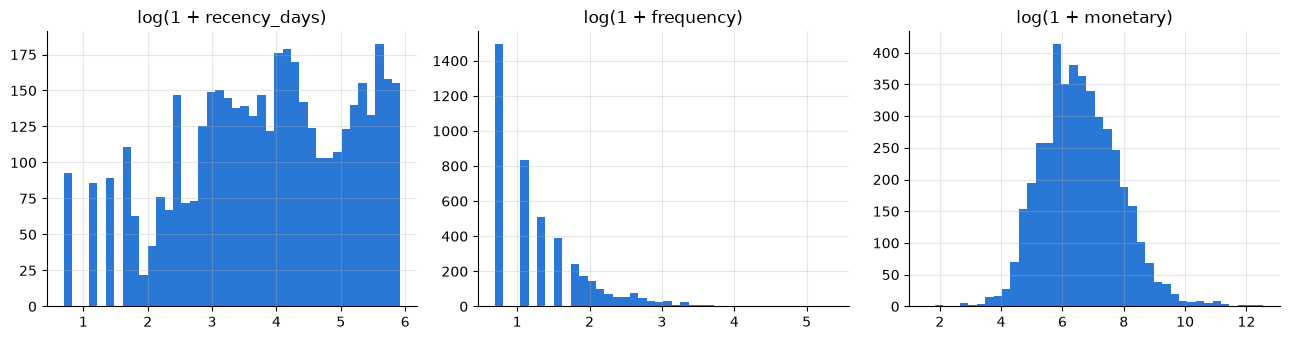

In [4]:
rfm = segment.rfm_table(tx)
fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))
for ax, col in zip(axes, rfm.columns):
    ax.hist(np.log1p(rfm[col]), bins=40, color=BLUE); ax.set_title(f"log(1 + {col})")
plt.tight_layout()
rfm.describe().round(1)

Heavily skewed (a few huge wholesale buyers), which is another reason to use percentile scores rather than raw values.

In [5]:
scores = segment.rfm_scores(rfm)
scores.describe().round(3)

,r_score,f_score,m_score
count,4338.000,4338.000,4338.000
mean,0.500,0.500,0.500
std,0.289,0.281,0.289
min,0.001,0.172,0.000
25%,0.250,0.172,0.250
50%,0.499,0.441,0.500
75%,0.748,0.771,0.750
max,0.989,1.000,1.000


## 3. Choosing k: elbow + silhouette

,k,inertia,silhouette
0,2,5778.123,0.456
1,3,4425.798,0.347
2,4,3244.399,0.383
3,5,2747.755,0.355
4,6,2335.861,0.352
5,7,2095.824,0.347
6,8,1915.364,0.336


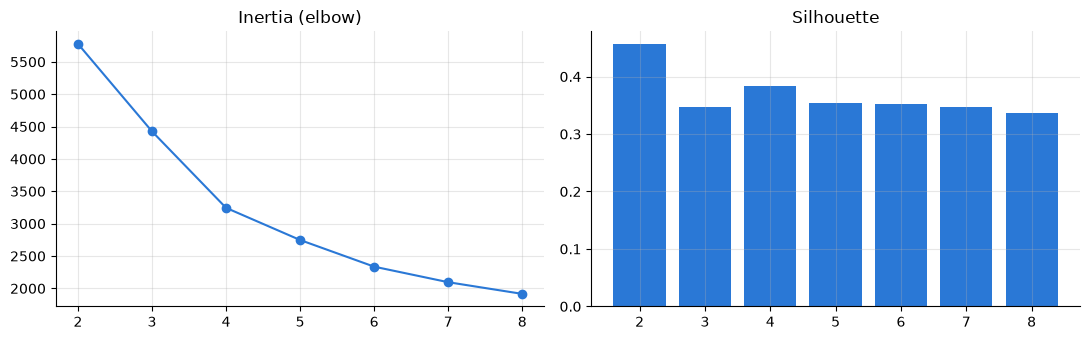

In [6]:
k_table = segment.evaluate_k(scores)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
axes[0].plot(k_table["k"], k_table["inertia"], marker="o", color=BLUE); axes[0].set_title("Inertia (elbow)")
axes[1].bar(k_table["k"], k_table["silhouette"], color=BLUE); axes[1].set_title("Silhouette")
plt.tight_layout(); k_table.round(3)

k=2 has the highest silhouette but only says "good vs bad". The inertia curve bends at
k=3-4, and k=4 maps onto the four standard RFM segments the sales team can act on, so we
take **k=4** and report its silhouette honestly alongside the others.

## 4. Fit, name and profile the segments

In [7]:
metrics = segment.train(save=True)
pd.DataFrame(metrics["profile"])

,segment,customers,recency_days,frequency,monetary
0,Champions,1289,13.0,7.0,2361.970
1,Loyal,826,24.0,2.0,352.985
2,At Risk,1014,83.5,3.0,981.520
3,Lost,1209,209.0,1.0,249.860


In [8]:
pd.DataFrame(metrics["centroids"]).T.round(3)

,r_score,f_score,m_score
At Risk,0.356,0.572,0.615
Champions,0.786,0.822,0.805
Lost,0.188,0.214,0.216
Loyal,0.689,0.328,0.299


Names come from centroids: highest R+F+M → **Champions**, lowest → **Lost**, of the middle two
the one with lower recency → **At Risk** (they used to buy), the other → **Loyal**.